# 06 · Decisão: janela de imunização regional × fev–ago e gatilho adaptativo

Pergunta (H4): uma janela de imunização regional, definida pela climatologia ou disparada pela previsão do início, cobre mais casos por semana de campanha que a janela nacional fixa de fevereiro a agosto? Método em `docs/METODOLOGIA.md` §14.

- **Janela climatológica (validação deixando uma temporada de fora, 2023–2025):**
  - curva de treino = média das curvas normalizadas (total 1) das outras temporadas;
  - para cada duração $L$, a janela de $L$ semanas com maior cobertura no treino é aplicada à temporada retirada;
  - `regional_90` = menor $L$ com cobertura ≥ 90% no treino.
  - `regional_mesma_dur` = janela regional com a mesma duração de fev–ago (comparação a custo igual).
- **Fev–ago:** semanas com a quarta-feira de fevereiro a agosto.
- **Gatilho adaptativo:** na origem com semana $s$ (SE 1–35, `05_marcos`), dispara se $P(\text{início} \le s + 3) > p$. A campanha dura o $L$ de `regional_90` a partir da semana do disparo.
  - Métricas: cobertura dos casos da temporada, antecedência (início real − disparo) e falso alarme (antecedência > 8 semanas ou sem disparo).
  - Baseline de *timing*: `naive_sazonal`.
- **Unidades:** Brasil, regiões e UFs do tier A. 2026 é avaliado com a temporada até a semana atual (cobertura provisória).
- **Saídas:** `decisao_janelas.parquet`, `decisao_curva.parquet` e `decisao_gatilho.parquet`.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import vsr_modelos as vm
from vsr_comum import JANELA_SUS, P, carregar_painel, verificar_ambiente

verificar_ambiente()
pd.set_option("display.width", 200); pd.set_option("display.max_columns", 40)
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3})

TIERS = pd.read_csv(P / "tiers_uf.csv").set_index("unidade")["tier"]
UNID = vm.AGREGADOS + sorted(TIERS[TIERS == "A"].index)
TEMP = [2023, 2024, 2025, 2026]
PAINEL = carregar_painel().query("unidade in @UNID and temporada in @TEMP")
K = 53
Y = {(u, t): g.set_index("semana_temporada")["vsr"].reindex(range(1, K + 1), fill_value=0).to_numpy(float)
     for (u, t), g in PAINEL.groupby(["unidade", "temporada"])}
MES = {t: ((g.drop_duplicates("semana_temporada").set_index("semana_temporada")["semana"] + pd.Timedelta(days=3))
           .dt.month.reindex(range(1, K + 1))) for t, g in PAINEL.groupby("temporada")}
VER = pd.read_parquet(P / "eda_marcos_temporada.parquet").query("serie == 'vsr'").set_index(["unidade", "temporada"])
print(len(UNID), "unidades;", "semana atual de 2026:", int(PAINEL.loc[PAINEL["temporada"] == 2026, "semana_temporada"].max()))


def melhor_janela(c: np.ndarray, L: int) -> int:
    """Início (0-based) da janela de L semanas com maior soma em c."""
    s = np.convolve(c, np.ones(L), "valid")
    return int(s.argmax())


def treino(u: str, t: int) -> np.ndarray:
    outras = [x for x in (2023, 2024, 2025) if x != t]
    return np.mean([Y[u, x] / Y[u, x].sum() for x in outras], axis=0)

21 unidades; semana atual de 2026: 41


## 1. Curva cobertura × duração (validação deixando uma temporada de fora)

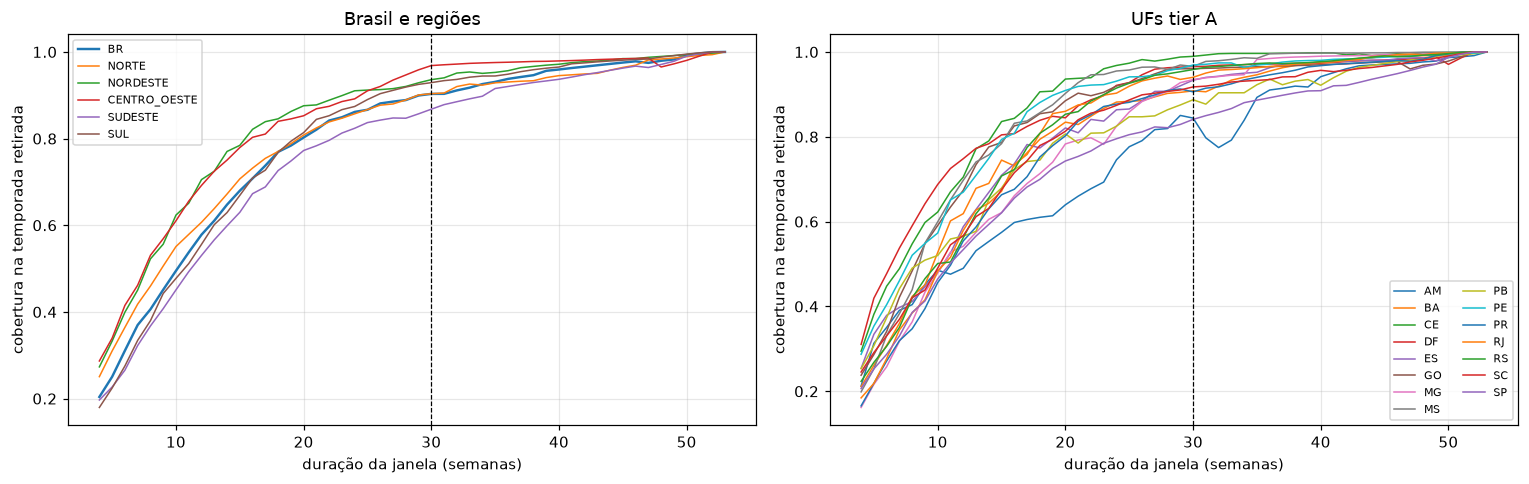

In [2]:
linhas = []
for u in UNID:
    for t in TEMP:
        c, y = treino(u, t), Y[u, t]
        for L in range(4, K + 1):
            i = melhor_janela(c, L)
            linhas.append({"unidade": u, "temporada": t, "L": L, "ini": i + 1, "cob_treino": c[i:i + L].sum(),
                           "cob": y[i:i + L].sum() / y.sum()})
CURVA = pd.DataFrame(linhas)
CURVA.to_parquet(P / "decisao_curva.parquet", index=False)

fig, axs = plt.subplots(1, 2, figsize=(14, 4.5))
for ax, grupo in zip(axs, (vm.AGREGADOS, sorted(TIERS[TIERS == "A"].index))):
    for u in grupo:
        g = CURVA.loc[(CURVA["unidade"] == u) & (CURVA["temporada"] < 2026)].groupby("L")["cob"].mean()
        ax.plot(g.index, g.values, label=u, lw=1.6 if u == "BR" else 1)
    ax.axvline(sum(m in range(JANELA_SUS[0], JANELA_SUS[1] + 1) for m in MES[2024].dropna()), color="k", ls="--", lw=0.8)
    ax.set_xlabel("duração da janela (semanas)"); ax.set_ylabel("cobertura na temporada retirada")
axs[0].legend(fontsize=7); axs[1].legend(fontsize=7, ncol=2); axs[0].set_title("Brasil e regiões"); axs[1].set_title("UFs tier A")
fig.tight_layout()

## 2. Janela regional de 90% × fev–ago

In [3]:
linhas = []
for u in UNID:
    for t in TEMP:
        g = CURVA.loc[(CURVA["unidade"] == u) & (CURVA["temporada"] == t)]
        r = g.loc[g["cob_treino"] >= 0.9].iloc[0]
        y, mes = Y[u, t], MES[t].to_numpy()
        fa = np.isin(mes, range(JANELA_SUS[0], JANELA_SUS[1] + 1))
        linhas += [{"unidade": u, "temporada": t, "estrategia": "regional_90", "ini": int(r["ini"]), "dur": int(r["L"]),
                    "cobertura": r["cob"]},
                   {"unidade": u, "temporada": t, "estrategia": "fev_ago", "ini": int(fa.argmax() + 1),
                    "dur": int(fa.sum()), "cobertura": y[fa].sum() / y.sum()}]
        r = g.loc[g["L"] == fa.sum()].iloc[0]          # regional com a mesma duração de fev–ago
        linhas.append({"unidade": u, "temporada": t, "estrategia": "regional_mesma_dur", "ini": int(r["ini"]),
                       "dur": int(r["L"]), "cobertura": r["cob"]})
JAN = pd.DataFrame(linhas)
JAN["cob_por_semana"] = JAN["cobertura"] / JAN["dur"]
JAN.to_parquet(P / "decisao_janelas.parquet", index=False)
JAN["grupo"] = np.where(JAN["unidade"].isin(vm.AGREGADOS), "BR + regiões", "UF A")
JAN["periodo"] = np.where(JAN["temporada"] == 2026, "2026 (provisório)", "2023–2025")
display(JAN.pivot_table(index=["grupo", "periodo", "estrategia"], values=["cobertura", "dur", "cob_por_semana"]).round(3))
display(JAN.loc[JAN["unidade"].isin(vm.AGREGADOS)].pivot_table(index=["unidade", "estrategia"], columns="temporada",
                                                              values=["ini", "dur", "cobertura"]).round(2))

cob_por_semana  cobertura     dur
grupo        periodo           estrategia                                           
BR + regiões 2023–2025         fev_ago                      0.030      0.920  30.333
                               regional_90                  0.035      0.877  25.944
                               regional_mesma_dur           0.030      0.920  30.333
             2026 (provisório) fev_ago                      0.032      0.962  30.000
                               regional_90                  0.035      0.900  26.333
                               regional_mesma_dur           0.031      0.934  30.000
UF A         2023–2025         fev_ago                      0.031      0.931  30.333
                               regional_90                  0.038      0.840  22.978
                               regional_mesma_dur           0.031      0.930  30.333
             2026 (provisório) fev_ago                      0.032      0.961  30.000
                               regional_90                  0.037      0.857  23.933
                               regional_mesma_dur           0.031      0.931  30.000

cobertura                     dur                     ini                  
temporada                            2023  2024  2025  2026  2023  2024  2025  2026  2023  2024  2025  2026
unidade      estrategia                                                                                    
BR           fev_ago                 0.87  0.94  0.95  0.97  31.0  30.0  30.0  30.0   5.0   6.0   6.0   5.0
             regional_90             0.79  0.94  0.93  0.95  24.0  30.0  30.0  28.0   9.0   5.0   3.0   6.0
             regional_mesma_dur      0.85  0.94  0.93  0.97  31.0  30.0  30.0  30.0   7.0   5.0   3.0   5.0
CENTRO_OESTE fev_ago                 0.89  0.95  0.97  0.98  31.0  30.0  30.0  30.0   5.0   6.0   6.0   5.0
             regional_90             0.79  0.93  0.87  0.85  19.0  22.0  22.0  22.0   8.0   5.0   2.0   5.0
             regional_mesma_dur      0.96  0.96  0.98  0.95  31.0  30.0  30.0  30.0   1.0   1.0   1.0   1.0
NORDESTE     fev_ago                 0.98  0.99  0.90  0.97  31.0  30.0  30.0  30.0   5.0   6.0   6.0   5.0
             regional_90             0.91  0.97  0.73  0.90  22.0  24.0  17.0  21.0  12.0  10.0  12.0  11.0
             regional_mesma_dur      0.96  0.98  0.88  0.96  31.0  30.0  30.0  30.0   9.0   9.0   4.0   8.0
NORTE        fev_ago                 0.93  0.93  0.84  0.93  31.0  30.0  30.0  30.0   5.0   6.0   6.0   5.0
             regional_90             0.95  0.88  0.82  0.77  31.0  28.0  25.0  28.0   8.0  12.0  11.0  11.0
             regional_mesma_dur      0.95  0.90  0.86  0.80  31.0  30.0  30.0  30.0   8.0  11.0   8.0  10.0
SUDESTE      fev_ago                 0.77  0.91  0.96  0.97  31.0  30.0  30.0  30.0   5.0   6.0   6.0   5.0
             regional_90             0.68  0.93  0.98  0.97  24.0  34.0  38.0  33.0   8.0   1.0   1.0   1.0
             regional_mesma_dur      0.77  0.90  0.95  0.94  31.0  30.0  30.0  30.0   5.0   1.0   1.0   1.0
SUL          fev_ago                 0.90  0.94  0.96  0.95  31.0  30.0  30.0  30.0   5.0   6.0   6.0   5.0
             regional_90             0.82  0.92  0.96  0.95  23.0  26.0  28.0  26.0  11.0   9.0   8.0   9.0
             regional_mesma_dur      0.89  0.95  0.96  0.98  31.0  30.0  30.0  30.0   8.0   8.0   6.0   8.0

## 3. Gatilho adaptativo

Distribuições de início de `05_marcos` (`previsoes_marcos.parquet`). Para cada unidade, temporada, modelo e limiar $p$: a primeira origem com $P(\text{início} \le s + 3) > p$ dispara uma campanha de $L$ = duração de `regional_90` (LOSO) a partir da semana $s$.

In [4]:
PM = pd.read_parquet(P / "previsoes_marcos.parquet").query("marco == 'inicio' and unidade in @UNID")
F = np.cumsum(PM[vm.COLS_P].to_numpy(), 1)
s = PM["semana_origem"].to_numpy()
PM["p4"] = F[np.arange(len(PM)), np.minimum(s + 3, K) - 1]
MODS = [m for m in ("naive_sazonal", "ensemble", "forma_curva", "ensemble_pond") if m in PM["modelo"].unique()]
DUR = JAN.query("estrategia == 'regional_90'").set_index(["unidade", "temporada"])["dur"]
linhas = []
for (u, t, m), g in PM.loc[PM["modelo"].isin(MODS)].groupby(["unidade", "temporada", "modelo"]):
    g = g.sort_values("semana_origem")
    y, ini_real = Y[u, t], VER.loc[(u, t), "inicio"]
    for p in np.round(np.arange(0.3, 0.91, 0.1), 1):
        dis = g.loc[g["p4"] > p, "semana_origem"]
        d = int(dis.iloc[0]) if len(dis) else np.nan
        L = int(DUR[u, t])
        cob = y[d - 1:d - 1 + L].sum() / y.sum() if len(dis) else 0.0
        ant = ini_real - d if len(dis) else np.nan
        linhas.append({"unidade": u, "temporada": t, "modelo": m, "p": p, "disparo": d, "dur": L, "cobertura": cob,
                       "antecedencia": ant, "falso_alarme": (not len(dis)) or ant > 8})
GAT = pd.DataFrame(linhas)
GAT.to_parquet(P / "decisao_gatilho.parquet", index=False)
GAT["grupo"] = np.where(GAT["unidade"].isin(vm.AGREGADOS), "BR + regiões", "UF A")
ref = JAN.pivot_table(index=["grupo", "estrategia"], values="cobertura").round(3)
display(GAT.loc[GAT["temporada"] < 2026].pivot_table(index=["grupo", "modelo", "p"],
        values=["cobertura", "antecedencia", "falso_alarme"]).round(2))
print("referência (2023–2026, LOSO):"); display(ref)

antecedencia  cobertura  falso_alarme
grupo        modelo        p                                         
BR + regiões ensemble      0.3          5.50       0.91          0.00
                           0.4          5.00       0.91          0.00
                           0.5          4.58       0.91          0.00
                           0.6          4.33       0.91          0.00
                           0.7          3.75       0.91          0.00
                           0.8          3.17       0.91          0.00
                           0.9          2.75       0.91          0.00
             ensemble_pond 0.3          5.50       0.91          0.00
                           0.4          5.00       0.91          0.00
                           0.5          4.67       0.91          0.00
                           0.6          4.33       0.91          0.00
                           0.7          3.75       0.91          0.00
                           0.8          3.25       0.91          0.00
                           0.9          2.67       0.91          0.00
             forma_curva   0.3          5.50       0.91          0.00
                           0.4          5.25       0.91          0.00
                           0.5          5.17       0.91          0.00
                           0.6          4.75       0.91          0.00
                           0.7          4.58       0.91          0.00
                           0.8          4.33       0.91          0.00
                           0.9          4.17       0.91          0.00
             naive_sazonal 0.3          4.75       0.91          0.00
                           0.4          4.33       0.91          0.00
                           0.5          4.08       0.91          0.00
                           0.6          3.50       0.91          0.00
                           0.7          3.33       0.91          0.00
                           0.8          2.83       0.90          0.00
                           0.9          2.25       0.90          0.00
UF A         ensemble      0.3          6.30       0.86          0.23
                           0.4          5.80       0.87          0.17
                           0.5          5.27       0.88          0.10
                           0.6          4.83       0.88          0.03
                           0.7          4.20       0.89          0.03
                           0.8          3.67       0.89          0.00
                           0.9          2.90       0.89          0.00
             ensemble_pond 0.3          6.30       0.86          0.23
                           0.4          5.80       0.87          0.17
                           0.5          5.27       0.88          0.13
                           0.6          4.83       0.88          0.03
                           0.7          4.23       0.89          0.03
                           0.8          3.73       0.89          0.00
                           0.9          2.90       0.89          0.00
             forma_curva   0.3          6.07       0.88          0.17
                           0.4          5.73       0.88          0.17
                           0.5          5.47       0.88          0.17
                           0.6          5.10       0.89          0.13
                           0.7          4.73       0.89          0.10
                           0.8          4.40       0.90          0.07
                           0.9          4.03       0.90          0.00
             naive_sazonal 0.3          5.60       0.86          0.17
                           0.4          5.23       0.86          0.17
                           0.5          4.87       0.87          0.13
                           0.6          4.60       0.87          0.13
                           0.7          4.20       0.87          0.07
                           0.8          3.83       0.88          0.00
                           0.9          3.

referência (2023–2026, LOSO):


cobertura
grupo        estrategia                   
BR + regiões fev_ago                 0.931
             regional_90             0.883
             regional_mesma_dur      0.924
UF A         fev_ago                 0.938
             regional_90             0.844
             regional_mesma_dur      0.930

## 4. Resumo

In [5]:
v = GAT.loc[GAT["temporada"] < 2026]
melhor = v.groupby(["grupo", "modelo", "p"])["cobertura"].mean().groupby(["grupo", "modelo"]).agg(["idxmax", "max"])
print("gatilho: melhor p por modelo (2024–2025):"); print(melhor.to_string())
j = JAN.loc[JAN["temporada"] < 2026].pivot_table(index="grupo", columns="estrategia", values=["cobertura", "dur"])
print("\njanelas (2023–2025, LOSO):"); print(j.round(3).to_string())

gatilho: melhor p por modelo (2024–2025):
                                                        idxmax       max
grupo        modelo                                                     
BR + regiões ensemble            (BR + regiões, ensemble, 0.6)  0.911745
             ensemble_pond  (BR + regiões, ensemble_pond, 0.6)  0.911745
             forma_curva      (BR + regiões, forma_curva, 0.9)  0.912636
             naive_sazonal  (BR + regiões, naive_sazonal, 0.6)  0.908914
UF A         ensemble                    (UF A, ensemble, 0.8)  0.893825
             ensemble_pond          (UF A, ensemble_pond, 0.9)  0.893775
             forma_curva              (UF A, forma_curva, 0.9)  0.902091
             naive_sazonal          (UF A, naive_sazonal, 0.9)  0.880237

janelas (2023–2025, LOSO):
             cobertura                                    dur                               
estrategia     fev_ago regional_90 regional_mesma_dur fev_ago regional_90 regional_mesma_dur
grupo         